# AgroSmart Puno · UNIDAD 2 — Sistema Big Data en tiempo real (S6 → S12)
**Estudiante:** Jose Armando Mamani Poccohuanca · **Equipo:** Jose Armando Mamani Poccohuanca y Mijael Yurins Coaquira Justo
**Pregunta central del proyecto:** ¿cómo anticipar a corto plazo las condiciones meteorológicas de riesgo agrícola del altiplano de Puno (estrés hídrico del suelo y heladas) a partir de datos de Open-Meteo?
**Dimensión de José:** *humedad del suelo* (¿qué humedad del suelo se espera en Puno 1, 2 y 3 h después?).
**DimensiónU2 (indicador streaming):** humedad del suelo en vivo y su predicción a +1, +2 y +3 h actualizándose dato por dato en el Grafana común.
**Alcance:** *solo humedad* — humedad del suelo 0–1 cm (objetivo, %) y humedad relativa del aire 2 m (complementaria, %). **Pronóstico a +1, +2 y +3 horas.**

```
Open-Meteo ──► producer_api_humedad ──► Kafka: ...-humedad-telemetria ─┬─► Spark Structured Streaming (consumer persistente)
 (API real)         ▲                                                  │      · eventos · ventanas 1 h · watermark 2 h · dedup · inferencia +1/+2/+3 h
 Carga inicial      │                                                  │                       │
 simulada (90 d) ───┘                       producer_evaluaciones ◄────┘                       ▼
 (PostgreSQL directo)                       └► Kafka: ...-humedad-empresarial ──────► PostgreSQL ──► Grafana (BI/ML)
                                                                                                └► Prometheus ◄─ exporter (observabilidad)
```

## Cómo se combinan datos simulados y datos reales (pedido del proyecto)
1. **Carga inicial (simulada):** 90 días horarios de humedad generados con un modelo calibrado a Puno (`origen='simulado_carga_inicial'`) se cargan al inicio en PostgreSQL → hay historia desde el primer minuto.
2. **Histórico API (real, modelado):** ~60 días de Open-Meteo (`origen='open_meteo_modelado'`).
3. **Tiempo real:** el productor *continuo* consulta la **misma API** cada 10 min y publica cada hora nueva en Kafka → Spark la procesa y predice.
4. **Entrenamiento:** simulado + API para tener más datos; **la prueba (último 15 %) cae siempre en datos reales de la API**, así la métrica no se infla con datos inventados.

> ⚠️ Honestidad científica: Open-Meteo es *modelado*, no sensores; la carga inicial es *simulada*. No se afirma capacidad agronómica ni generalización a sondas físicas.

## Orden de ejecución (los comandos de CMD están en cada paso y en `GUIA_EJECUCION_CMD.md`)
| Orden | Sesión | Qué se hace | Dónde |
|---|---|---|---|
| 0 | — | Entorno y servicios | este cuaderno |
| 1 | **S06** | Eventos empresariales en Kafka | CMD + este cuaderno |
| 2 | **S07** | Ingesta IoT/API, registros descargados y carga inicial | este cuaderno + CMD |
| 3 | **S08** | Spark Structured Streaming: consumer, **monitor en tiempo real**, SQL, watermark y checkpoints | CMD + este cuaderno |
| 4 | **S09** | Observabilidad (Prometheus/Grafana) y costos en S/ | CMD + este cuaderno |
| 5 | **S10** | Series de tiempo: entrenar +1, +2 y +3 h e inferencia | este cuaderno |
| 6 | **S11** | BI/ML en Grafana | Grafana + este cuaderno |

> La **primera vez** que se monta el proyecto, ejecuta la sección **10.1** (entrenar) antes de arrancar el consumer de la S08; después, el cuaderno se recorre en orden S06 → S11.

---
# 0 · Entorno y verificación de servicios
Desde la **raíz del proyecto** (CMD) ya debes tener levantados Kafka y PostgreSQL+Jupyter (ver guía). Spark del cuaderno es **solo batch/ML**; el streaming corre en otro contenedor (`spark-consumer`).

In [1]:
from pathlib import Path
from datetime import datetime, timezone, timedelta
import os, sys, json, math, time, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import psycopg2
from psycopg2.extras import execute_values
from pyspark.sql import SparkSession, functions as F
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import LinearRegression, RandomForestRegressor, DecisionTreeRegressor, GBTRegressor
from pyspark.ml.evaluation import RegressionEvaluator

RAIZ = Path(os.environ.get('AGRO_ROOT', '/home/jovyan/work/Sensorhumedad'))
REPO = Path('/home/jovyan/agrosmart-repo')
for p in ('datos', 'datos/bronze', 'modelos', 'resultados', 'evidencias', 'checkpoints'):
    (RAIZ/p).mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(REPO/'uso-agrosmart'/'producer'))
KAFKA = os.getenv('KAFKA_BOOTSTRAP', 'kafka:9092')
TOP_TEL = 'agrosmart-u2-humedad-telemetria'
TOP_EMP = 'agrosmart-u2-humedad-empresarial'
LAT, LON, UBIC = -15.84, -70.02, 'Puno'
PARAM_DB = dict(host=os.getenv('POSTGRES_HOST', 'postgres'), dbname=os.getenv('POSTGRES_DB', 'agrosmart_u2'),
                user=os.getenv('POSTGRES_USER', 'agrosmart'), password=os.getenv('POSTGRES_PASSWORD', ''), connect_timeout=10)

def sql(consulta, params=None, columnas=True):
    with psycopg2.connect(**PARAM_DB) as con, con.cursor() as cur:
        cur.execute(consulta, params)
        if cur.description is None: return None
        filas = cur.fetchall()
        return pd.DataFrame(filas, columns=[d[0] for d in cur.description]) if columnas else filas

print('Carpeta de trabajo:', RAIZ, '| Ejecución UTC:', datetime.now(timezone.utc).isoformat())
print('PostgreSQL:', sql('SELECT version()', columnas=False)[0][0][:50])
# Crear/actualizar tablas (idempotente)
with psycopg2.connect(**PARAM_DB) as con, con.cursor() as cur:
    cur.execute((REPO/'pyspark'/'sql'/'schema.sql').read_text(encoding='utf-8'))
print('Tablas:', sql("SELECT table_name FROM information_schema.tables WHERE table_schema='public' ORDER BY 1").table_name.tolist())

spark = (SparkSession.builder.master('local[2]').appName('AgroSmart-U2-Batch-ML')
         .config('spark.sql.shuffle.partitions', '2').config('spark.sql.session.timeZone', 'UTC').getOrCreate())
spark.sparkContext.setLogLevel('WARN'); print('Spark', spark.version)

Carpeta de trabajo: /home/jovyan/work/Sensorhumedad | Ejecución UTC: 2026-11-20T17:16:15.995678+00:00
PostgreSQL: PostgreSQL 16.15 on x86_64-pc-linux-musl, compiled
Tablas: ['api_descargas', 'comparacion_modelos', 'comparacion_modelos_temperatura', 'ejecuciones_integracion', 'escenarios_costos', 'eventos_empresariales', 'eventos_empresariales_temperatura', 'eventos_telemetria', 'eventos_temperatura', 'metricas_modelo', 'metricas_modelo_temperatura', 'metricas_pipeline', 'predicciones_humedad', 'predicciones_temperatura', 'ventanas_humedad', 'ventanas_temperatura']
Spark 3.5.0


In [2]:
# ¿Kafka responde? (kafka-python desde el contenedor Jupyter, red agrosmart-jose-kafka-net)
from kafka import KafkaAdminClient
try:
    adm = KafkaAdminClient(bootstrap_servers=KAFKA, request_timeout_ms=8000)
    print('Kafka OK. Tópicos existentes:', sorted(adm.list_topics())); adm.close()
except Exception as e:
    print('⚠️ Kafka no responde:', e, '\n→ En CMD: docker compose --env-file .env -f kafka/compose.yml up -d')

Kafka OK. Tópicos existentes: ['__consumer_offsets', 'agrosmart-u2-humedad-empresarial', 'agrosmart-u2-humedad-telemetria', 'agrosmart-u2-temperatura-empresarial', 'agrosmart-u2-temperatura-telemetria']


---
# SESIÓN 06 · Ingesta de eventos empresariales en tiempo real (Kafka)
**Idea:** además de la telemetría, un *evento de negocio* nace de cada lectura: una **evaluación simulada** de humedad para la gestión de riego (`seguimiento` o `revision_manual`). No se inventan ventas ni litros; el **umbral 20 %** es *solo didáctico*.

**Conceptos S6 aplicados:** tópico, partición, offset, productor/consumidor, contrato de datos (JSON Schema), idempotencia (`evento_id` determinista), `acks=all`.

## 6.1 Contrato de datos (qué campos y límites acepta el sistema)

In [3]:
for nombre in ('telemetria.json', 'telemetria.schema.json', 'empresa.json', 'empresarial.schema.json'):
    ruta = REPO/'uso-agrosmart'/'contratos'/nombre
    print('=====', nombre); print(ruta.read_text(encoding='utf-8')[:900])

===== telemetria.json
{
  "evento_id": "uuid-de-ejemplo",
  "fecha_evento": "2026-11-05T15:00:00+00:00",
  "ubicacion": "Puno",
  "humedad_suelo_pct": 18.4,
  "humedad_aire_pct": 64.0,
  "origen": "open_meteo_modelado",
  "humedad_suelo_m3m3": 0.184,
  "modo_publicacion": "replay_historico",
  "profundidad_suelo_cm": "0-1",
  "emitido_utc": "2026-11-05T15:00:05+00:00"
}
===== telemetria.schema.json
{
  "$schema": "https://json-schema.org/draft/2020-12/schema",
  "title": "Evento humedad Open-Meteo modelado (S7)",
  "type": "object",
  "required": ["evento_id","fecha_evento","ubicacion","humedad_suelo_m3m3","humedad_suelo_pct","humedad_aire_pct","origen","modo_publicacion","emitido_utc"],
  "properties": {
    "evento_id": {"type":"string", "minLength":16},
    "fecha_evento": {"type":"string", "format":"date-time"},
    "ubicacion": {"type":"string"},
    "humedad_suelo_m3m3": {"type":"number", "minimum":0, "maximum":1},
    "humedad_suelo_pct": {"type":"number", "minimum":0, "maximum"

## 6.2 Regla de negocio simulada (probada sin Kafka)

In [4]:
from decisiones import crear_evaluacion
ejemplo = {'evento_id': 'abc123', 'fecha_evento': '2026-11-13T12:00:00Z', 'ubicacion': UBIC, 'humedad_suelo_pct': 14.2, 'humedad_aire_pct': 38.0}
print(json.dumps(crear_evaluacion(ejemplo, 20.0), indent=2, ensure_ascii=False))
print('Con 25 % de suelo →', crear_evaluacion({**ejemplo, 'humedad_suelo_pct': 25.0})['estado'])

{
  "evento_id": "eval-abc123",
  "evento_telemetria_id": "abc123",
  "fecha_evento": "2026-11-13T12:00:00Z",
  "ubicacion": "Puno",
  "tipo": "evaluacion_humedad",
  "estado": "revision_manual",
  "humedad_suelo_pct": 14.2,
  "humedad_aire_pct": 38.0,
  "umbral_demo_pct": 20.0,
  "origen": "decision_empresarial_simulada_desde_open_meteo",
  "creado_utc": "2026-11-20T17:16:19.967113+00:00"
}
Con 25 % de suelo → seguimiento


## 6.3 Crear los dos tópicos (una partición/replicación 1 = laboratorio, no HA)
**Opción CMD (recomendada, ejecuta el contenedor `agrosmart-jose-uso`):**
```bat
docker compose --env-file .env -f uso-agrosmart/compose.yml --profile herramientas run --rm inicializar-topicos
```
Opción dentro del cuaderno (equivalente, idempotente):

In [5]:
from kafka import KafkaAdminClient
from kafka.admin import NewTopic
from kafka.errors import TopicAlreadyExistsError
adm = KafkaAdminClient(bootstrap_servers=KAFKA)
for t in (TOP_TEL, TOP_EMP):
    try: adm.create_topics([NewTopic(name=t, num_partitions=1, replication_factor=1)]); print('creado', t)
    except TopicAlreadyExistsError: print('ya existe', t)
print(sorted(x for x in adm.list_topics() if x.startswith('agrosmart'))); adm.close()

ya existe agrosmart-u2-humedad-telemetria
ya existe agrosmart-u2-humedad-empresarial
['agrosmart-u2-humedad-empresarial', 'agrosmart-u2-humedad-telemetria', 'agrosmart-u2-temperatura-empresarial', 'agrosmart-u2-temperatura-telemetria']


## 6.4 Derivador de eventos empresariales (S6) — en CMD
```bat
docker compose --env-file .env -f uso-agrosmart/compose.yml --profile flujo up -d producer-evaluaciones
docker compose --env-file .env -f uso-agrosmart/compose.yml logs --tail=40 producer-evaluaciones
```
Este proceso **consume** la telemetría y **publica** una evaluación en el tópico empresarial (dos productores distinguibles: API→telemetría y evaluaciones→empresarial).

---
# SESIÓN 07 · Ingesta de eventos IoT/sensores en tiempo real
Aquí la «telemetría» es **la misma API** (Open-Meteo) que actúa como fuente de eventos horarios.
## 7.1 Consultar la API: humedad del suelo 0–1 cm y humedad del aire 2 m

In [6]:
from open_meteo_humedad import consultar_api, guardar_bronze
registros, metadata = consultar_api(LAT, LON, dias=60, ubicacion=UBIC)
guardar_bronze(RAIZ/'datos'/'bronze'/'consulta_entrenamiento.json', registros, metadata)
api = pd.DataFrame(registros)
api['fecha_evento'] = pd.to_datetime(api['fecha_evento'], utc=True)
api = api.loc[api.fecha_evento <= pd.Timestamp.now(tz='UTC')].drop_duplicates('fecha_evento').sort_values('fecha_evento').reset_index(drop=True)
api.to_csv(RAIZ/'datos'/'historico_open_meteo.csv', index=False)
print('Registros API (Forecast, últimos 60 días):', len(api), '| rango:', api.fecha_evento.min(), '→', api.fecha_evento.max())
print('Fuente:', metadata['fuente']); print('Unidades:', metadata['unidades'])
display(api.tail())

Registros API (Forecast, últimos 60 días): 1458 | rango: 2026-09-21 00:00:00+00:00 → 2026-11-20 17:00:00+00:00
Fuente: Open-Meteo Forecast API; modelos meteorológicos, no sensores
Unidades: {'time': 'iso8601', 'soil_moisture_0_to_1cm': 'm³/m³', 'relative_humidity_2m': '%'}


,evento_id,fecha_evento,ubicacion,humedad_suelo_m3m3,humedad_suelo_pct,humedad_aire_pct,origen,profundidad_suelo_cm
1453,5009e106e5f5eb981fea7a1651aad26e,2026-11-20 13:00:00+00:00,Puno,0.150,15.0,39.0,open_meteo_modelado,0-1
1454,369834bde34d55df8cd4ebffbea47f21,2026-11-20 14:00:00+00:00,Puno,0.149,14.9,41.0,open_meteo_modelado,0-1
1455,74073f683912bf0a045e8dd718369666,2026-11-20 15:00:00+00:00,Puno,0.148,14.8,40.0,open_meteo_modelado,0-1
1456,d8595d112ed998e86445884cf6ed40d0,2026-11-20 16:00:00+00:00,Puno,0.146,14.6,36.0,open_meteo_modelado,0-1
1457,dce73ca0d60b489a38379d2236f95d7b,2026-11-20 17:00:00+00:00,Puno,0.145,14.5,35.0,open_meteo_modelado,0-1


## 7.2 Todo lo descargado de la API Open-Meteo (tiempo real + histórico)
Además de la consulta de los últimos 60 días (Forecast API, la que alimenta el modelo de streaming), el proyecto descargó el
**histórico horario 2012–2026** de la misma Open-Meteo (Historical Weather API, reanálisis ERA5) en el cuaderno
`Historico_BigData`. Aquí se cargan ambos para mostrar el volumen total descargado de la API y se registra en PostgreSQL
(tabla `api_descargas`) para que Grafana lo muestre. El histórico de suelo es de la capa **0–7 cm** (la de 0–1 cm no existe en el archivo), por eso **no se mezcla** con el entrenamiento del modelo de 0–1 cm: se usa para volumen, análisis y el modelo del cuaderno histórico.

REGISTROS DESCARGADOS DE LA API OPEN-METEO · HUMEDAD: 131 778


,fuente,registros,desde,hasta
0,Forecast API · últimos 60 días (streaming y mo...,1458,2026-09-21,2026-11-20
1,Historical API ERA5 · histórico 2012–2026 (sue...,130320,2012-01-01,2026-11-12


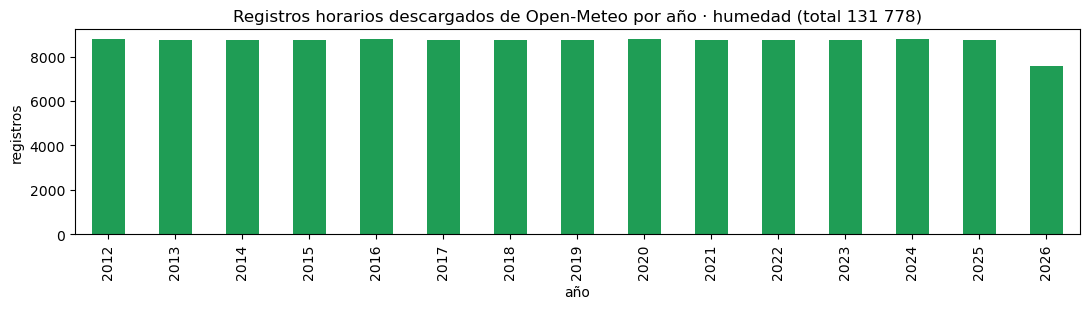

In [7]:
import glob
GOLD_HIST = Path('/home/jovyan/work/Historico_BigData/gold/humedad')
if not GOLD_HIST.exists():
    raise FileNotFoundError('Falta el histórico: ejecuta antes Historico_BigData/U3_BigData_Historico_OpenMeteo.ipynb')
hist = pd.read_parquet(GOLD_HIST)                     # Parquet Gold particionado por anio/mes (pyarrow)
hist['fecha'] = pd.to_datetime(hist['fecha'])
hist['fecha'] = (hist.fecha.dt.tz_localize('UTC') if hist.fecha.dt.tz is None else hist.fecha).dt.tz_convert('America/Lima')   # hora de Perú
resumen_api = pd.DataFrame([
    {'fuente': 'Forecast API · últimos 60 días (streaming y modelo U2)', 'registros': len(api),
      'desde': api.fecha_evento.min().strftime('%Y-%m-%d'), 'hasta': api.fecha_evento.max().strftime('%Y-%m-%d')},
    {'fuente': 'Historical API ERA5 · histórico 2012–2026 (suelo 0–7 cm + aire 2 m)', 'registros': len(hist),
      'desde': hist.fecha.min().strftime('%Y-%m-%d'), 'hasta': hist.fecha.max().strftime('%Y-%m-%d')}])
TOTAL_API = int(resumen_api.registros.sum())
print(f'REGISTROS DESCARGADOS DE LA API OPEN-METEO · HUMEDAD: {TOTAL_API:,}'.replace(',', ' '))
display(resumen_api)

with psycopg2.connect(**PARAM_DB) as con, con.cursor() as cur:
    cur.execute('''CREATE TABLE IF NOT EXISTS api_descargas (dimension TEXT, fuente TEXT, registros BIGINT, desde DATE, hasta DATE,
                   actualizado TIMESTAMPTZ DEFAULT NOW(), PRIMARY KEY (dimension, fuente))''')
    for r in resumen_api.itertuples():
        cur.execute('''INSERT INTO api_descargas (dimension, fuente, registros, desde, hasta) VALUES (%s,%s,%s,%s,%s)
                       ON CONFLICT (dimension, fuente) DO UPDATE SET registros=EXCLUDED.registros, desde=EXCLUDED.desde,
                       hasta=EXCLUDED.hasta, actualizado=NOW()''', ('humedad', r.fuente, int(r.registros), r.desde, r.hasta))

por_anio = hist.groupby(hist.fecha.dt.year).size()
ax = por_anio.plot(kind='bar', figsize=(11, 3.2), color='#1f9d55', title=f'Registros horarios descargados de Open-Meteo por año · humedad (total {TOTAL_API:,})'.replace(',', ' '))
ax.set_xlabel('año'); ax.set_ylabel('registros'); plt.tight_layout(); plt.savefig(RAIZ/'resultados'/'api_descargas_por_anio.png', dpi=120); plt.show()

## 7.3 Calidad y variabilidad (sin inventar cambios)
La humedad del suelo puede cambiar muy poco durante horas (valores repetidos). Se valida rango, huecos y variación antes de entrenar.

In [8]:
for c in ['humedad_suelo_pct', 'humedad_aire_pct']:
    assert api[c].between(0, 100).all(), f'{c}: fuera de 0-100'
huecos = api.fecha_evento.diff().dropna()
print('Huecos distintos de 1 h:', int((huecos != pd.Timedelta(hours=1)).sum()))
res = api[['humedad_suelo_pct', 'humedad_aire_pct']].agg(['count', 'min', 'max', 'mean', 'std', 'nunique']).T
res['rango'] = res['max'] - res['min']; display(res)
print('Cambio absoluto horario del suelo: mediana', api.humedad_suelo_pct.diff().abs().median(), '| % de horas sin cambio:', round((api.humedad_suelo_pct.diff() == 0).mean()*100, 1))

Huecos distintos de 1 h: 0


,count,min,max,mean,std,nunique,rango
humedad_suelo_pct,1458.0,6.8,38.6,16.532442,7.222606,254.0,31.8
humedad_aire_pct,1458.0,4.0,100.0,46.294925,26.584956,97.0,96.0


Cambio absoluto horario del suelo: mediana 0.0 | % de horas sin cambio: 54.0


## 7.4 CARGA INICIAL (simulada) — se hace **antes** de recibir datos en tiempo real
Se simulan **90 días** que terminan 1 h antes del inicio del histórico API (continuidad temporal). Se guardan en CSV y se insertan en `eventos_telemetria` con `origen='simulado_carga_inicial'`. Es **idempotente** (`ON CONFLICT DO NOTHING`).

In [9]:
from simulador_humedad import simular
DIAS_SIM = 90
sim = pd.DataFrame(simular(api.fecha_evento.min().to_pydatetime(), dias=DIAS_SIM, semilla=42, ubicacion=UBIC))
sim['fecha_evento'] = pd.to_datetime(sim['fecha_evento'], utc=True)
sim.to_csv(RAIZ/'datos'/'simulado_carga_inicial.csv', index=False)
print(f'Simulado: {len(sim)} filas  {sim.fecha_evento.min()} → {sim.fecha_evento.max()}')
assert (api.fecha_evento.min() - sim.fecha_evento.max()) == pd.Timedelta(hours=1), 'hay hueco entre simulado y API'

filas = [(r.evento_id, r.fecha_evento.isoformat(), r.fecha_evento.isoformat(), r.ubicacion, r.humedad_suelo_m3m3,
          r.humedad_suelo_pct, r.humedad_aire_pct, r.origen, 'carga_inicial') for r in sim.itertuples()]
with psycopg2.connect(**PARAM_DB) as con, con.cursor() as cur:
    execute_values(cur, '''INSERT INTO eventos_telemetria
        (evento_id,fecha_evento,emitido_utc,ubicacion,humedad_suelo_m3m3,humedad_suelo_pct,humedad_aire_pct,origen,modo_publicacion)
        VALUES %s ON CONFLICT(evento_id) DO NOTHING''', filas, page_size=500)
display(sql("SELECT origen, COUNT(*) filas, MIN(fecha_evento) desde, MAX(fecha_evento) hasta FROM eventos_telemetria GROUP BY origen ORDER BY desde"))

Simulado: 2160 filas  2026-06-23 00:00:00+00:00 → 2026-09-20 23:00:00+00:00


,origen,filas,desde,hasta
0,simulado_carga_inicial,4314,2026-06-19 19:00:00-05:00,2026-09-20 18:00:00-05:00
1,open_meteo_modelado,86,2026-11-02 22:00:00-05:00,2026-11-18 21:00:00-05:00
2,open_meteo_interpolado_2min,1551,2026-11-16 16:10:00-05:00,2026-11-20 12:16:00-05:00


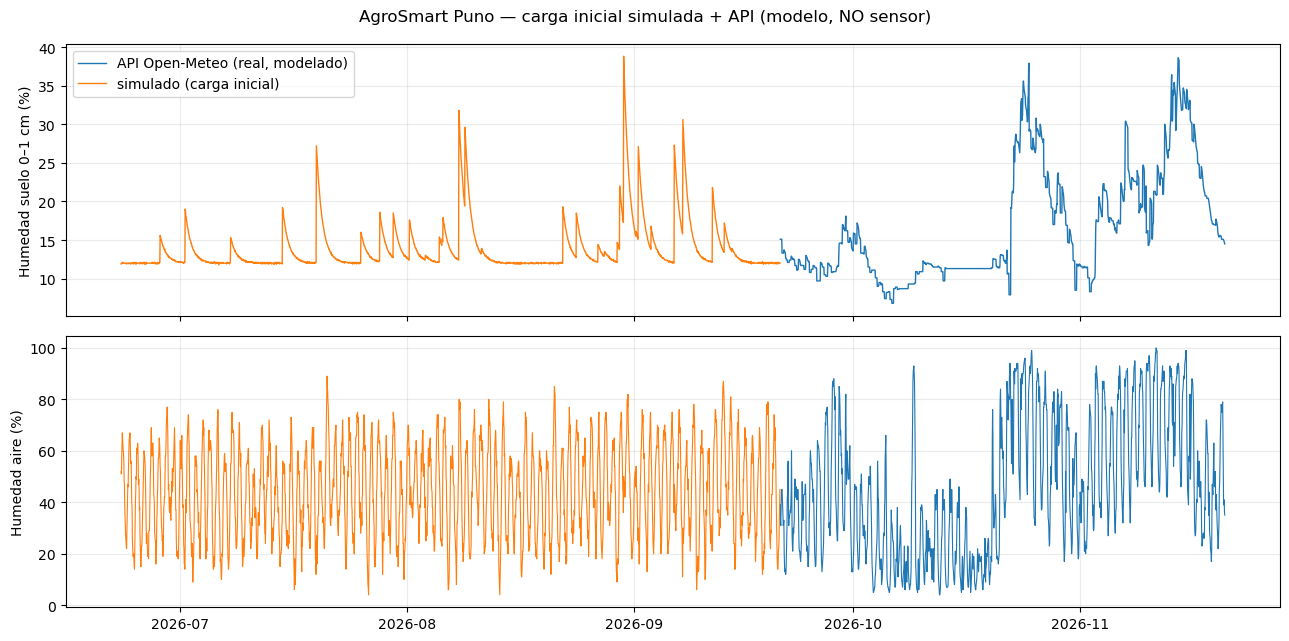

In [10]:
comb = pd.concat([sim.assign(fuente='simulado (carga inicial)'), api.assign(fuente='API Open-Meteo (real, modelado)')]).sort_values('fecha_evento')
fig, ax = plt.subplots(2, 1, figsize=(13, 6.5), sharex=True)
for f, g in comb.groupby('fuente'):
    ax[0].plot(g.fecha_evento, g.humedad_suelo_pct, lw=1, label=f); ax[1].plot(g.fecha_evento, g.humedad_aire_pct, lw=.8, label=f)
ax[0].set_ylabel('Humedad suelo 0–1 cm (%)'); ax[1].set_ylabel('Humedad aire (%)'); ax[0].legend(); ax[0].grid(alpha=.25); ax[1].grid(alpha=.25)
fig.suptitle('AgroSmart Puno — carga inicial simulada + API (modelo, NO sensor)'); plt.tight_layout()
fig.savefig(RAIZ/'resultados'/'humedades_api.png', dpi=160, bbox_inches='tight'); plt.show()

## 7.5 Replay de la API hacia Kafka y modo continuo (tiempo real) — en CMD
```bat
:: Replay académico: publica las últimas 72 horas de la API en Kafka (verás offsets)
docker compose --env-file .env -f uso-agrosmart/compose.yml --profile replay run --rm producer-api-replay

:: Tiempo real: consulta la API cada 10 min y publica cada hora nueva (déjalo corriendo)
docker compose --env-file .env -f uso-agrosmart/compose.yml --profile continuo up -d producer-api-continuo
docker compose --env-file .env -f uso-agrosmart/compose.yml logs -f producer-api-continuo
```
**Nota:** si no llega un evento nuevo en un buen rato **no significa que Kafka esté caído**: la API publica una estimación por hora y el productor evita repetir valores idénticos.

> ⚠️ Para ver llegar datos al Spark Consumer, primero entrena los modelos (sección 10.1) y arranca el consumer (Paso 4).

### ⏱️ Flujo cada **2 minutos** (humedad de José + temperatura de Mijael)
Open-Meteo solo publica estimaciones **horarias** de modelo (la humedad del suelo no existe a menor resolución) y no hay API pública gratuita con humedad del suelo observada cada 2 min para esta zona. Por eso el productor de 2 min **consulta Open-Meteo (caché de 10 min) y calcula el valor de cada instante por interpolación lineal entre las dos horas que lo rodean**; cada evento va etiquetado `origen='open_meteo_interpolado_2min'`. **No es una medición de sensor.**
```bat
docker compose --env-file .env -f uso-agrosmart/compose.yml --profile tiempo-real-2min up -d producer-humedad-2min producer-temperatura-2min
docker compose --env-file .env -f uso-agrosmart/compose.yml logs -f producer-humedad-2min producer-temperatura-2min
```
Úsalo **en lugar de** `producer-api-continuo` / `producer-temp-continuo` para no mezclar cadencias. En el monitor del Paso 4.2 sube `ESPERA` a 30 s y `N` a 10 para ver crecer los contadores cada 2 min. Los modelos y consumers no cambian: el horizonte (+1/+2/+3 h) se cuenta desde la fecha de cada evento.

---
# SESIÓN 08 · Procesamiento en streaming con Spark (ventanas, watermark, checkpoints)
> **Requisito:** el consumer usa los modelos guardados en la **Sesión 10** (`modelos/`). Si es la primera vez que corres el proyecto, ejecuta antes la sección **10.1** y luego arranca el consumer; después de eso, el orden de este cuaderno (S6 → S11) se sigue tal cual.

El **consumer persistente** (`pyspark/scripts/consumer_streaming.py`) corre con `spark-submit` en **otro contenedor** (no en Jupyter), igual que un *Job Cluster* en producción. Lanza **3 consultas**:

| Consulta | Lee | Hace | Checkpoint |
|---|---|---|---|
| `telemetria` | tópico telemetría | guarda eventos + **infiere +1/+2/+3 h** | `checkpoints/telemetria` |
| `empresarial` | tópico empresarial | guarda evaluaciones | `checkpoints/empresarial` |
| `ventanas` | tópico telemetría | **ventanas de 1 h**, **watermark 2 h**, dedup | `checkpoints/ventanas` |

- **Ventana (tumbling):** agrupa lecturas por hora de evento. **Watermark 2 h:** tolera retraso hasta 2 h; un evento *más tardío* que el watermark ya no entra en la ventana. **Checkpoint:** guarda offsets/estado para reanudar sin perder ni duplicar. **Idempotencia:** `ON CONFLICT DO NOTHING` por `evento_id`.

## 8.1 Arrancar el consumer (CMD, **después** de entrenar los modelos)
```bat
docker compose --env-file .env -f pyspark/compose.yml -f pyspark/compose.kafka.yml --profile streaming up -d spark-consumer
docker compose --env-file .env -f pyspark/compose.yml -f pyspark/compose.kafka.yml logs --tail=80 spark-consumer
```
Debes ver **3 consultas iniciadas**. La primera vez descarga el conector Spark-Kafka de Maven (necesita internet y tarda unos minutos).

## 8.2 Ver llegar los datos (en vivo) desde el cuaderno

In [11]:
def estado():
    t = sql('''SELECT (SELECT COUNT(*) FROM eventos_telemetria) AS telemetria,
                      (SELECT COUNT(*) FROM eventos_telemetria WHERE origen='open_meteo_modelado') AS api,
                      (SELECT COUNT(*) FROM eventos_empresariales) AS empresariales,
                      (SELECT COUNT(*) FROM predicciones_humedad) AS predicciones,
                      (SELECT COUNT(*) FROM ventanas_humedad) AS ventanas''')
    t.insert(0, 'hora_utc', datetime.now(timezone.utc).strftime('%H:%M:%S')); return t

# Monitor: 6 lecturas cada 10 s (cambia N o ESPERA para vigilar más tiempo; Ctrl+C para detener)
N, ESPERA = 6, 10
serie = []
for i in range(N):
    serie.append(estado()); display(serie[-1].tail(1).set_index('hora_utc'))
    if i < N-1: time.sleep(ESPERA)
print('Si los contadores suben al publicar con el replay/continuo, el flujo Kafka → Spark → PostgreSQL funciona.')

,telemetria,api,empresariales,predicciones,ventanas
hora_utc,,,,,
17:16:25,5951,86,1637,4911,145


,telemetria,api,empresariales,predicciones,ventanas
hora_utc,,,,,
17:16:35,5951,86,1637,4911,145


,telemetria,api,empresariales,predicciones,ventanas
hora_utc,,,,,
17:16:45,5951,86,1637,4911,145


,telemetria,api,empresariales,predicciones,ventanas
hora_utc,,,,,
17:16:55,5951,86,1637,4911,145


,telemetria,api,empresariales,predicciones,ventanas
hora_utc,,,,,
17:17:05,5951,86,1637,4911,145


,telemetria,api,empresariales,predicciones,ventanas
hora_utc,,,,,
17:17:15,5951,86,1637,4911,145


Si los contadores suben al publicar con el replay/continuo, el flujo Kafka → Spark → PostgreSQL funciona.


In [12]:
from kafka import KafkaConsumer, TopicPartition
def ultimos(topico, n=5):
    c = KafkaConsumer(bootstrap_servers=KAFKA, enable_auto_commit=False, consumer_timeout_ms=6000,
                      value_deserializer=lambda b: json.loads(b.decode('utf-8')))
    tp = [TopicPartition(topico, p) for p in (c.partitions_for_topic(topico) or [])]
    if not tp: c.close(); return None, {}
    c.assign(tp); fin = c.end_offsets(tp); ini = c.beginning_offsets(tp)
    for t in tp: c.seek(t, max(ini[t], fin[t]-n))
    msgs = [(m.partition, m.offset, m.value) for m in c]; c.close()
    return msgs, {f'{t.topic}[{t.partition}]': (ini[t], fin[t]) for t in tp}
for top in (TOP_TEL, TOP_EMP):
    msgs, offs = ultimos(top, 3)
    print('=====', top, '| offsets (inicio, fin):', offs)
    for p, o, v in (msgs or []): print(f'  p{p} off={o}', {k: v[k] for k in list(v)[:6]})

===== agrosmart-u2-humedad-telemetria | offsets (inicio, fin): {'agrosmart-u2-humedad-telemetria[0]': (0, 1623)}
  p0 off=1620 {'evento_id': '5adfe27df465db5975629931d286059d', 'fecha_evento': '2026-11-20T12:12:00-05:00', 'ubicacion': 'Puno', 'humedad_suelo_m3m3': 0.1448, 'humedad_suelo_pct': 14.48, 'humedad_aire_pct': 35.8}
  p0 off=1621 {'evento_id': '8b9f7e93261c336d418aa7e8be72a469', 'fecha_evento': '2026-11-20T12:14:00-05:00', 'ubicacion': 'Puno', 'humedad_suelo_m3m3': 0.144767, 'humedad_suelo_pct': 14.4767, 'humedad_aire_pct': 35.933}
  p0 off=1622 {'evento_id': '25354e46cca45e948eb240cdc3f414ba', 'fecha_evento': '2026-11-20T12:16:00-05:00', 'ubicacion': 'Puno', 'humedad_suelo_m3m3': 0.144733, 'humedad_suelo_pct': 14.4733, 'humedad_aire_pct': 36.067}
===== agrosmart-u2-humedad-empresarial | offsets (inicio, fin): {'agrosmart-u2-humedad-empresarial[0]': (0, 1623)}
  p0 off=1620 {'evento_id': 'eval-5adfe27df465db5975629931d286059d', 'evento_telemetria_id': '5adfe27df465db5975629931

## 8.3 Monitor en tiempo real (José): lo que llega cada 2 minutos
Muestra en el cuaderno lo mismo que la ventana **1 PRODUCTOR HUMEDAD**: cada evento que llega a Kafka (`fecha`, `valor`, `offset`) y, al lado, las **predicciones +1, +2 y +3 h** que Spark Structured Streaming guardó en PostgreSQL para ese mismo evento. Empieza con los 5 últimos mensajes y luego espera los nuevos durante `MINUTOS`.

In [13]:
# 8.3 · MONITOR EN TIEMPO REAL — lo que llega a Kafka y lo que Spark guarda y predice (igual que la ventana del productor)
import time
from kafka import KafkaConsumer, TopicPartition
MINUTOS = 4   # tiempo de observación: llega un evento nuevo cada 2 minutos
PREVIOS = 5   # últimos mensajes ya publicados, para no empezar con la pantalla vacía

def prediccion_spark(evento_id, espera_s):
    """Busca en PostgreSQL lo que Spark Structured Streaming guardó para ese evento."""
    for _ in range(espera_s):
        with psycopg2.connect(**PARAM_DB) as con, con.cursor() as cur:
            cur.execute("SELECT horizonte_h, ROUND(prediccion_pct::numeric, 2) FROM predicciones_humedad WHERE evento_id = %s ORDER BY horizonte_h", (evento_id,))
            filas = cur.fetchall()
        if filas:
            return filas
        time.sleep(1)
    return []

consumidor = KafkaConsumer(bootstrap_servers=KAFKA, enable_auto_commit=False, consumer_timeout_ms=1000,
                           value_deserializer=lambda b: json.loads(b.decode('utf-8')))
particiones = [TopicPartition(TOP_TEL, p) for p in consumidor.partitions_for_topic(TOP_TEL)]
consumidor.assign(particiones)
for tp, fin in consumidor.end_offsets(particiones).items():
    consumidor.seek(tp, max(0, fin - PREVIOS))

print(f'Escuchando {TOP_TEL} durante {MINUTOS} min · hora de Perú · un evento cada 2 min\n', flush=True)
limite = time.time() + MINUTOS * 60
while time.time() < limite:
    for m in consumidor:
        e = m.value
        nuevo = time.time() - m.timestamp / 1000 < 60          # recién publicado: se espera a que Spark lo procese
        preds = prediccion_spark(e['evento_id'], espera_s=30 if nuevo else 2)
        txt = ' · '.join(f'+{h} h {p} %' for h, p in preds) if preds else 'aún sin predicción'
        print(f"[HUMEDAD] fecha={e['fecha_evento']} valor={e['humedad_suelo_pct']} % offset={m.offset}  →  Spark: {txt}", flush=True)
consumidor.close()
print('\nFin del monitoreo. Vuelve a ejecutar la celda para seguir viendo el flujo.')

Escuchando agrosmart-u2-humedad-telemetria durante 4 min · hora de Perú · un evento cada 2 min

[HUMEDAD] fecha=2026-11-20T12:08:00-05:00 valor=14.4867 % offset=1618  →  Spark: +1 h 14.47 % · +2 h 14.47 % · +3 h 14.43 %
[HUMEDAD] fecha=2026-11-20T12:10:00-05:00 valor=14.4833 % offset=1619  →  Spark: +1 h 14.47 % · +2 h 14.47 % · +3 h 14.43 %
[HUMEDAD] fecha=2026-11-20T12:12:00-05:00 valor=14.48 % offset=1620  →  Spark: +1 h 14.47 % · +2 h 14.46 % · +3 h 14.43 %
[HUMEDAD] fecha=2026-11-20T12:14:00-05:00 valor=14.4767 % offset=1621  →  Spark: +1 h 14.46 % · +2 h 14.46 % · +3 h 14.43 %
[HUMEDAD] fecha=2026-11-20T12:16:00-05:00 valor=14.4733 % offset=1622  →  Spark: +1 h 14.46 % · +2 h 14.46 % · +3 h 14.42 %
[HUMEDAD] fecha=2026-11-20T12:18:00-05:00 valor=14.47 % offset=1623  →  Spark: +1 h 14.46 % · +2 h 14.45 % · +3 h 14.42 %
[HUMEDAD] fecha=2026-11-20T12:20:00-05:00 valor=14.4667 % offset=1624  →  Spark: +1 h 14.45 % · +2 h 14.45 % · +3 h 14.42 %

Fin del monitoreo. Vuelve a ejecutar la

## 8.4 Consultas SQL de verificación (eventos, ventanas, estado de las 3 consultas)

In [14]:
print('Estado de las consultas Spark (heartbeat):'); display(sql('''SELECT consulta,activa,batch_id,filas_entrada,duracion_ms,retraso_offsets,observado_utc,error
                                                                 FROM metricas_pipeline ORDER BY consulta'''))
print('Últimas ventanas de 1 h:'); display(sql('SELECT * FROM ventanas_humedad ORDER BY inicio DESC LIMIT 8'))
print('Evaluaciones empresariales por estado:'); display(sql('''SELECT estado, COUNT(*) eventos, ROUND(AVG(humedad_suelo_pct)::numeric,2) suelo_medio
                                                              FROM eventos_empresariales GROUP BY estado'''))
print('Últimos eventos de telemetría:'); display(sql('SELECT fecha_evento,humedad_suelo_pct,humedad_aire_pct,origen,modo_publicacion FROM eventos_telemetria ORDER BY fecha_evento DESC LIMIT 6'))

Estado de las consultas Spark (heartbeat):


,consulta,activa,batch_id,filas_entrada,duracion_ms,retraso_offsets,observado_utc,error
0,empresarial,True,1582,0,2.0,0.0,2026-11-20 12:21:19.661174-05:00,None
1,telemetria,True,1582,0,2.0,0.0,2026-11-20 12:21:19.661174-05:00,None
2,temp_empresarial,True,1595,0,4.0,0.0,2026-11-20 12:21:25.056107-05:00,None
3,temp_telemetria,True,1595,0,4.0,0.0,2026-11-20 12:21:25.056107-05:00,None
4,temp_ventanas,True,1595,0,3.0,0.0,2026-11-20 12:21:25.056107-05:00,None
5,ventanas,True,1582,0,2.0,0.0,2026-11-20 12:21:19.661174-05:00,None


Últimas ventanas de 1 h:


,inicio,fin,ubicacion,lecturas,humedad_suelo_media_pct,humedad_aire_media_pct
0,2026-11-20 12:00:00-05:00,2026-11-20 13:00:00-05:00,Puno,11,14.483336,35.666636
1,2026-11-20 11:00:00-05:00,2026-11-20 12:00:00-05:00,Puno,19,14.533332,35.333316
2,2026-11-20 05:00:00-05:00,2026-11-20 06:00:00-05:00,Puno,12,15.500000,77.800000
3,2026-11-20 04:00:00-05:00,2026-11-20 05:00:00-05:00,Puno,30,15.500000,79.483333
4,2026-11-20 03:00:00-05:00,2026-11-20 04:00:00-05:00,Puno,30,15.500000,79.000000
5,2026-11-20 02:00:00-05:00,2026-11-20 03:00:00-05:00,Puno,30,15.380000,76.916667
6,2026-11-20 01:00:00-05:00,2026-11-20 02:00:00-05:00,Puno,30,15.251667,72.000000
7,2026-11-20 00:00:00-05:00,2026-11-20 01:00:00-05:00,Puno,30,15.300000,72.516667


Evaluaciones empresariales por estado:


,estado,eventos,suelo_medio
0,seguimiento,802,21.59
1,revision_manual,837,16.29


Últimos eventos de telemetría:


,fecha_evento,humedad_suelo_pct,humedad_aire_pct,origen,modo_publicacion
0,2026-11-20 12:20:00-05:00,14.4667,36.333,open_meteo_interpolado_2min,interpolado_2min
1,2026-11-20 12:18:00-05:00,14.4700,36.200,open_meteo_interpolado_2min,interpolado_2min
2,2026-11-20 12:16:00-05:00,14.4733,36.067,open_meteo_interpolado_2min,interpolado_2min
3,2026-11-20 12:14:00-05:00,14.4767,35.933,open_meteo_interpolado_2min,interpolado_2min
4,2026-11-20 12:12:00-05:00,14.4800,35.800,open_meteo_interpolado_2min,interpolado_2min
5,2026-11-20 12:10:00-05:00,14.4833,35.667,open_meteo_interpolado_2min,interpolado_2min


## 8.5 Prueba de watermark y de checkpoints (S8)
**Evento tardío** (publica un evento con fecha muy anterior, *después* de que el watermark avanzó):
```bat
docker compose --env-file .env -f uso-agrosmart/compose.yml --profile pruebas run --rm producer-evento-tardio
```
Comprueba que Kafka lo recibió (offset nuevo) y busca su `evento_id` en `eventos_telemetria` / ventanas. **Si el watermark avanzó lo suficiente, no debería sumarse a una ventana cerrada.** *No afirmes el resultado sin comprobarlo.*

**Checkpoint / reinicio sin duplicados:**
```bat
docker compose --env-file .env -f pyspark/compose.yml -f pyspark/compose.kafka.yml stop spark-consumer
docker compose --env-file .env -f pyspark/compose.yml -f pyspark/compose.kafka.yml --profile streaming up -d spark-consumer
```
Luego compara conteos antes/después (4.2) y verifica ausencia de duplicados:

In [15]:
display(sql('''SELECT 'eventos_telemetria' tabla, COUNT(*) filas, COUNT(DISTINCT evento_id) ids_unicos FROM eventos_telemetria
               UNION ALL SELECT 'predicciones_humedad', COUNT(*), COUNT(DISTINCT (evento_id||'-'||horizonte_h)) FROM predicciones_humedad'''))
print('Directorios de checkpoint:', sorted(p.name for p in (RAIZ/'checkpoints').iterdir()) if (RAIZ/'checkpoints').exists() else 'sin crear aún')

,tabla,filas,ids_unicos
0,eventos_telemetria,5953,5953
1,predicciones_humedad,4917,4917


Directorios de checkpoint: ['.gitkeep', 'empresarial', 'telemetria', 'ventanas']


---
# SESIÓN 09 · Observabilidad con Prometheus/Grafana y costos
## 9.1 Levantar Prometheus + exportador + Grafana (CMD)
```bat
docker compose --env-file .env -f obs/compose.yml up -d --build
```
| Servicio | URL |
|---|---|
| Prometheus Targets (todos **UP**) | http://localhost:9095/targets |
| Exportador PostgreSQL (`agrosmart_*`) | http://localhost:9202/metrics |
| Exportador Kafka | http://localhost:49309/metrics |
| Grafana (usuario/clave de `.env`) | http://localhost:3300 |
| Kafka UI | http://localhost:48086 |

**Alertas** (`obs/prometheus/alerts.yml`) son *técnicas* (servicio caído, consulta inactiva, datos sin procesar), **no** recomendaciones agronómicas. `UP=1` no prueba que cada microlote funcione: confirma también filas y logs.

## 9.2 Consultar Prometheus desde el cuaderno

In [16]:
import requests
PROM = 'http://prometheus:9090'      # alcanzable porque Jupyter y Prometheus comparten agrosmart-jose-kafka-net
def prom(q):
    r = requests.get(f'{PROM}/api/v1/query', params={'query': q}, timeout=8); r.raise_for_status()
    return r.json()['data']['result']
try:
    for q in ['up', 'agrosmart_consulta_activa', 'agrosmart_duracion_lote_ms', 'agrosmart_retraso_offsets']:
        res = prom(q); print(f'{q:30s}', [(x['metric'].get('job') or x['metric'].get('consulta'), x['value'][1]) for x in res][:6])
    objetivos = requests.get(f'{PROM}/api/v1/targets', timeout=8).json()['data']['activeTargets']
    display(pd.DataFrame([{'job': t['labels']['job'], 'estado': t['health'], 'url': t['scrapeUrl']} for t in objetivos]))
except Exception as e:
    print('⚠️ Prometheus no responde (¿levantaste obs/compose.yml?):', e)
try: print('Grafana /api/health:', requests.get('http://grafana:3000/api/health', timeout=8).json())
except Exception as e: print('⚠️ Grafana no responde:', e)

up                             [('pushgateway', '1'), ('agrosmart_exporter', '1'), ('prometheus', '1'), ('kafka_exporter', '1')]
agrosmart_consulta_activa      [('agrosmart_exporter', '1'), ('agrosmart_exporter', '1'), ('agrosmart_exporter', '1'), ('agrosmart_exporter', '1'), ('agrosmart_exporter', '1'), ('agrosmart_exporter', '1')]
agrosmart_duracion_lote_ms     [('agrosmart_exporter', '3'), ('agrosmart_exporter', '3'), ('agrosmart_exporter', '3'), ('agrosmart_exporter', '2'), ('agrosmart_exporter', '2'), ('agrosmart_exporter', '2')]
agrosmart_retraso_offsets      [('agrosmart_exporter', '0'), ('agrosmart_exporter', '0'), ('agrosmart_exporter', '0'), ('agrosmart_exporter', '0'), ('agrosmart_exporter', '0'), ('agrosmart_exporter', '0')]


,job,estado,url
0,agrosmart_exporter,up,http://exporter:9200/metrics
1,kafka_exporter,up,http://kafka-exporter:9308/metrics
2,prometheus,up,http://prometheus:9090/metrics
3,pushgateway,up,http://pushgateway:9091/metrics


Grafana /api/health: {'database': 'ok', 'version': '11.5.2', 'commit': '598e0338d5374d6bc404b02a58094132c5eeceb8'}


## 9.3 Costos en soles (S/) — escenarios y supuestos explícitos
Las tarifas **S/ 0.30/h de cómputo y S/ 0.40/GB-mes** son **supuestos didácticos editables**, no precios comerciales. Se guardan en `escenarios_costos` (Grafana los muestra).

In [17]:
r = subprocess.run([sys.executable, str(REPO/'pyspark'/'scripts'/'costos_pen.py'), '--tarifa-computo-hora', '0.30', '--tarifa-gb-mes', '0.40'],
                   capture_output=True, text=True, env=os.environ)
print(r.stdout[-2500:] or r.stderr[-1500:])
display(sql('SELECT nombre,eventos_hora,eventos_mes,ROUND(total_pen::numeric,2) total_pen FROM escenarios_costos ORDER BY eventos_hora'))

Costos parciales estimados en SOLES (S/); NO son tarifas de un proveedor
1_eventos_hora: S/ 216.00 / mes, 0.000849 GB aprox.
24_eventos_hora: S/ 216.01 / mes, 0.020373 GB aprox.
240_eventos_hora: S/ 216.08 / mes, 0.203731 GB aprox.
Escenarios S/ guardados también en PostgreSQL para Grafana
Reporte: /home/jovyan/work/Sensorhumedad/resultados/costos_pen.json



,nombre,eventos_hora,eventos_mes,total_pen
0,1 eventos/h,1,720,216.00
1,24 eventos/h,24,17280,216.01
2,240 eventos/h,240,172800,216.08


Complementa en CMD con mediciones reales de recursos (para justificar el dimensionamiento):
```bat
docker stats --no-stream
docker compose ls
```

---
# SESIÓN 10 · Series de tiempo: entrenamiento e inferencia
## 10.1 Entrenar modelos de +1, +2 y +3 horas
**Se entrena aquí (batch) porque el consumer streaming necesita los modelos guardados.** Esto es la *batch layer* de Lambda.

**Diseño (series de tiempo ≠ regresión simple, S4):**
- Predictores en el instante *t*: humedad del suelo, humedad del aire, hora (seno/coseno).
- Objetivo: humedad del suelo en *t + h* (h = 1, 2, 3).
- **División cronológica** 70 % / 15 % / 15 % con **brecha de *h* filas** (para que la etiqueta no cruce al segmento siguiente). Nunca se baraja.
- Cuatro algoritmos MLlib (Lineal, Random Forest, Árbol, GBT) **contra el baseline de persistencia** (*predicción = valor actual*). **Se elige con validación; la prueba mide generalización** (y son datos **reales de la API**).
- **Datos:** simulado (carga inicial) + API.

In [18]:
base = pd.concat([sim, api]).drop_duplicates('fecha_evento').sort_values('fecha_evento').reset_index(drop=True)
base['hora'] = base.fecha_evento.dt.hour
base['hora_seno'] = np.sin(2*np.pi*base.hora/24); base['hora_coseno'] = np.cos(2*np.pi*base.hora/24)
vars_ml = ['humedad_suelo_pct', 'humedad_aire_pct', 'hora_seno', 'hora_coseno']
print(f'Base de entrenamiento: {len(base):,} horas  (simulado {len(sim):,} + API {len(api):,})  {base.fecha_evento.min()} → {base.fecha_evento.max()}')
print('Huecos horarios en la base:', int((base.fecha_evento.diff().dropna() != pd.Timedelta(hours=1)).sum()))

Base de entrenamiento: 3,618 horas  (simulado 2,160 + API 1,458)  2026-06-23 00:00:00+00:00 → 2026-11-20 17:00:00+00:00
Huecos horarios en la base: 0


In [19]:
modelos, metricas, comparaciones = {}, [], []
rmse_eval = RegressionEvaluator(labelCol='label', predictionCol='prediction', metricName='rmse')
mae_eval  = RegressionEvaluator(labelCol='label', predictionCol='prediction', metricName='mae')
r2_eval   = RegressionEvaluator(labelCol='label', predictionCol='prediction', metricName='r2')

for h in (1, 2, 3):
    d = base.copy()
    d['fecha_objetivo'] = d.fecha_evento.shift(-h); d['label'] = d.humedad_suelo_pct.shift(-h)
    delta = (d.fecha_objetivo - d.fecha_evento).dt.total_seconds()
    d = d.loc[delta == h*3600].dropna(subset=vars_ml + ['label']).reset_index(drop=True)
    a_, b_ = int(len(d)*.7), int(len(d)*.85)
    if a_-h < 50 or b_-a_-h < 25 or len(d)-b_ < 25: raise RuntimeError(f'Histórico insuficiente en horizonte {h}')
    train = spark.createDataFrame(d.iloc[:a_-h][vars_ml+['label']].astype(float))
    val   = spark.createDataFrame(d.iloc[a_:b_-h][vars_ml+['label']].astype(float))
    test  = spark.createDataFrame(d.iloc[b_:][vars_ml+['label']].astype(float))
    baseline_rmse = rmse_eval.evaluate(test.withColumn('prediction', F.col('humedad_suelo_pct')))
    candidatos = {
      'RegresionLineal': LinearRegression(featuresCol='features', labelCol='label', maxIter=60),
      'RandomForest': RandomForestRegressor(featuresCol='features', labelCol='label', numTrees=40, maxDepth=6, seed=42),
      'ArbolDecision': DecisionTreeRegressor(featuresCol='features', labelCol='label', maxDepth=6, seed=42),
      'GradientBoostedTrees': GBTRegressor(featuresCol='features', labelCol='label', maxIter=20, maxDepth=4, seed=42)}
    ajustados = {}
    for nombre, est in candidatos.items():
        aj = Pipeline(stages=[VectorAssembler(inputCols=vars_ml, outputCol='features'), est]).fit(train)
        ajustados[nombre] = (rmse_eval.evaluate(aj.transform(val)), aj)
    ganador = min(ajustados, key=lambda n: ajustados[n][0]); mg = ajustados[ganador][1]
    for nombre, (rv, m) in ajustados.items():
        pt = m.transform(test)
        comparaciones.append(dict(horizonte_h=h, modelo=nombre, rmse_validacion=rv, rmse_prueba=rmse_eval.evaluate(pt),
            mae_prueba=mae_eval.evaluate(pt), r2_prueba=r2_eval.evaluate(pt), seleccionado=(nombre == ganador)))
    sel = mg.transform(test)
    metricas.append(dict(horizonte_h=h, modelo=ganador, rmse=rmse_eval.evaluate(sel), mae=mae_eval.evaluate(sel), r2=r2_eval.evaluate(sel),
        rmse_validacion=ajustados[ganador][0], baseline_rmse=baseline_rmse, n_train=train.count(), n_validacion=val.count(), n_prueba=test.count()))
    modelos[h] = mg
    mg.write().overwrite().save(str(RAIZ/'modelos'/f'humedad_{h}h'))
    print(f'+{h} h | mejor en validación: {ganador:22s} | RMSE prueba {metricas[-1]["rmse"]:.4f} pp | persistencia {baseline_rmse:.4f} pp')

metricas_df = pd.DataFrame(metricas); comparacion_df = pd.DataFrame(comparaciones)
metricas_df.to_csv(RAIZ/'resultados'/'metricas_modelo.csv', index=False)
comparacion_df.to_csv(RAIZ/'resultados'/'comparacion_cuatro_modelos.csv', index=False)
print('MODELOS ELEGIDOS (3):'); display(metricas_df.round(4))
print('TODOS LOS CANDIDATOS (12):'); display(comparacion_df.round(4))

+1 h | mejor en validación: RegresionLineal        | RMSE prueba 1.1579 pp | persistencia 1.0943 pp
+2 h | mejor en validación: RegresionLineal        | RMSE prueba 1.7620 pp | persistencia 1.6219 pp
+3 h | mejor en validación: RegresionLineal        | RMSE prueba 2.2595 pp | persistencia 2.0285 pp
MODELOS ELEGIDOS (3):


,horizonte_h,modelo,rmse,mae,r2,rmse_validacion,baseline_rmse,n_train,n_validacion,n_prueba
0,1,RegresionLineal,1.1579,0.6005,0.9712,0.9185,1.0943,2530,542,543
1,2,RegresionLineal,1.7620,1.0753,0.9333,1.3515,1.6219,2529,540,543
2,3,RegresionLineal,2.2595,1.4656,0.8902,1.6970,2.0285,2527,539,543


TODOS LOS CANDIDATOS (12):


,horizonte_h,modelo,rmse_validacion,rmse_prueba,mae_prueba,r2_prueba,seleccionado
0,1,RegresionLineal,0.9185,1.1579,0.6005,0.9712,True
1,1,RandomForest,2.1302,3.4389,2.2758,0.7458,False
2,1,ArbolDecision,2.1033,3.4977,2.1466,0.7370,False
3,1,GradientBoostedTrees,2.0938,3.5292,2.1816,0.7322,False
4,2,RegresionLineal,1.3515,1.7620,1.0753,0.9333,True
5,2,RandomForest,2.2752,3.6750,2.4995,0.7097,False
6,2,ArbolDecision,2.1083,3.7210,2.4382,0.7023,False
7,2,GradientBoostedTrees,2.1722,3.7235,2.3910,0.7019,False
8,3,RegresionLineal,1.6970,2.2595,1.4656,0.8902,True
9,3,RandomForest,2.4111,3.9574,2.7857,0.6633,False


### Cómo leer el resultado (importante para la sustentación)
- El RMSE está en **puntos porcentuales** de humedad volumétrica (no es % relativo).
- Si el modelo elegido **no supera** a la persistencia en algún horizonte, **se dice tal cual**: con series muy persistentes (autocorrelación ≈ 0.99) la persistencia es un rival muy fuerte y la mejora real suele estar en los horizontes largos o en los picos.
- El conjunto de **prueba es 100 % datos reales de la API** (es el segmento más reciente).

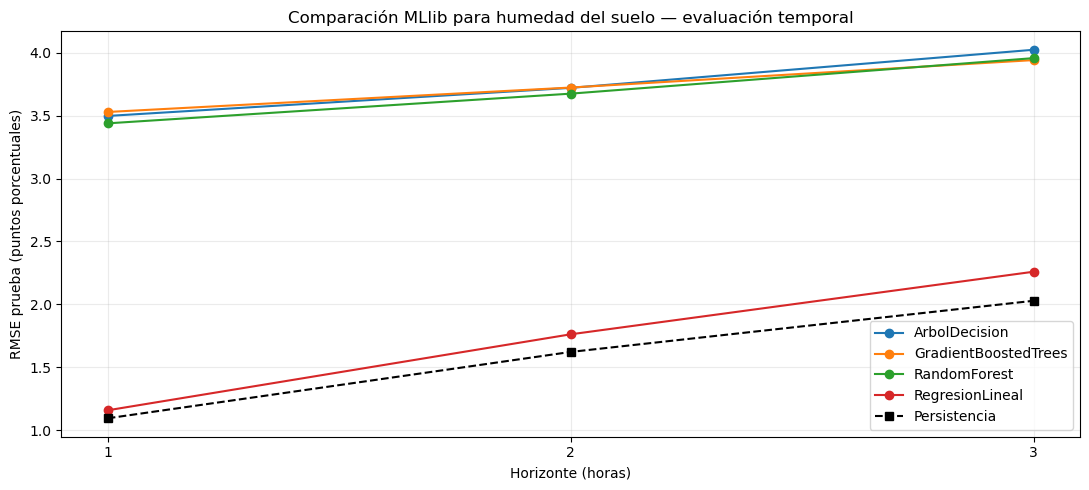

In [20]:
fig, ax = plt.subplots(figsize=(11, 5))
for nombre, g in comparacion_df.groupby('modelo'): ax.plot(g.horizonte_h, g.rmse_prueba, marker='o', label=nombre)
ax.plot(metricas_df.horizonte_h, metricas_df.baseline_rmse, ls='--', marker='s', color='k', label='Persistencia')
ax.set_xticks([1, 2, 3]); ax.set_xlabel('Horizonte (horas)'); ax.set_ylabel('RMSE prueba (puntos porcentuales)')
ax.set_title('Comparación MLlib para humedad del suelo — evaluación temporal'); ax.grid(alpha=.25); ax.legend(); plt.tight_layout()
fig.savefig(RAIZ/'resultados'/'comparacion_modelos.png', dpi=170, bbox_inches='tight'); plt.show()

## 10.2 Guardar métricas en PostgreSQL (las muestra Grafana)

In [21]:
with psycopg2.connect(**PARAM_DB) as con, con.cursor() as cur:
    for m in metricas:
        cur.execute('''INSERT INTO metricas_modelo (horizonte_h,modelo,rmse,mae,r2,rmse_validacion,baseline_rmse,n_train,n_validacion,n_prueba)
          VALUES (%s,%s,%s,%s,%s,%s,%s,%s,%s,%s) ON CONFLICT(horizonte_h) DO UPDATE SET modelo=EXCLUDED.modelo,rmse=EXCLUDED.rmse,
          mae=EXCLUDED.mae,r2=EXCLUDED.r2,rmse_validacion=EXCLUDED.rmse_validacion,baseline_rmse=EXCLUDED.baseline_rmse,
          n_train=EXCLUDED.n_train,n_validacion=EXCLUDED.n_validacion,n_prueba=EXCLUDED.n_prueba,fecha_registro=NOW()''',
          tuple(m[k] for k in ['horizonte_h','modelo','rmse','mae','r2','rmse_validacion','baseline_rmse','n_train','n_validacion','n_prueba']))
    for m in comparaciones:
        cur.execute('''INSERT INTO comparacion_modelos (horizonte_h,modelo,rmse_validacion,rmse_prueba,mae_prueba,r2_prueba,seleccionado)
          VALUES (%s,%s,%s,%s,%s,%s,%s) ON CONFLICT(horizonte_h,modelo) DO UPDATE SET rmse_validacion=EXCLUDED.rmse_validacion,
          rmse_prueba=EXCLUDED.rmse_prueba,mae_prueba=EXCLUDED.mae_prueba,r2_prueba=EXCLUDED.r2_prueba,seleccionado=EXCLUDED.seleccionado,fecha_registro=NOW()''',
          tuple(m[k] for k in ['horizonte_h','modelo','rmse_validacion','rmse_prueba','mae_prueba','r2_prueba','seleccionado']))
print('Modelos en disco:', sorted(p.name for p in (RAIZ/'modelos').iterdir() if p.name.startswith('humedad_')))
display(sql('SELECT * FROM metricas_modelo ORDER BY horizonte_h'))

Modelos en disco: ['humedad_1h', 'humedad_2h', 'humedad_3h']


,horizonte_h,modelo,rmse,mae,r2,rmse_validacion,baseline_rmse,n_train,n_validacion,n_prueba,fecha_registro
0,1,RegresionLineal,1.157913,0.600540,0.971176,0.918484,1.094310,2530,542,543,2026-11-20 12:22:30.752513-05:00
1,2,RegresionLineal,1.761967,1.075265,0.933259,1.351522,1.621858,2529,540,543,2026-11-20 12:22:30.752513-05:00
2,3,RegresionLineal,2.259514,1.465571,0.890244,1.697017,2.028530,2527,539,543,2026-11-20 12:22:30.752513-05:00


---
## 10.3 Inferencia: predicción de humedad a +1, +2 y +3 horas
El consumer predice **cada evento que llega**. Aquí además hacemos un **pronóstico «ahora»** con la última lectura disponible y los **modelos guardados** (mismo `PipelineModel` que usa el streaming → evita *drift* batch/streaming) y lo registramos en `predicciones_humedad`.

`es_retro=TRUE` significa que la hora objetivo **ya ocurrió** (replay histórico → predicción retrospectiva); `es_retro=FALSE` es una predicción **prospectiva** (objetivo en el futuro). **No los mezcles al evaluar.**

In [22]:
ult = sql('''SELECT evento_id,fecha_evento,humedad_suelo_pct,humedad_aire_pct,origen FROM eventos_telemetria
              WHERE fecha_evento <= NOW() ORDER BY fecha_evento DESC LIMIT 1''').iloc[0]
f0 = pd.Timestamp(ult.fecha_evento).tz_convert('UTC'); print('Última lectura:', f0, '| suelo', ult.humedad_suelo_pct, '% | aire', ult.humedad_aire_pct, '% | origen', ult.origen)
fila = pd.DataFrame([{'humedad_suelo_pct': float(ult.humedad_suelo_pct), 'humedad_aire_pct': float(ult.humedad_aire_pct),
                      'hora_seno': math.sin(2*math.pi*f0.hour/24), 'hora_coseno': math.cos(2*math.pi*f0.hour/24)}])
sdf = spark.createDataFrame(fila)
pron = []
for h in (1, 2, 3):
    m = PipelineModel.load(str(RAIZ/'modelos'/f'humedad_{h}h'))
    p = float(m.transform(sdf).select('prediction').collect()[0][0])
    objetivo = f0 + pd.Timedelta(hours=h)
    pron.append(dict(horizonte_h=h, fecha_objetivo=objetivo, prediccion_pct=round(p, 3), persistencia_pct=float(ult.humedad_suelo_pct),
                     modelo=m.stages[-1].__class__.__name__, es_retro=bool(pd.Timestamp.now(tz='UTC') >= objetivo)))
pron_df = pd.DataFrame(pron); display(pron_df)
with psycopg2.connect(**PARAM_DB) as con, con.cursor() as cur:
    for r in pron:
        cur.execute('''INSERT INTO predicciones_humedad (evento_id,horizonte_h,fecha_evento,fecha_objetivo,prediccion_pct,modelo,es_retro)
                       VALUES (%s,%s,%s,%s,%s,%s,%s) ON CONFLICT(evento_id,horizonte_h) DO NOTHING''',
                    (ult.evento_id, r['horizonte_h'], f0.to_pydatetime(), r['fecha_objetivo'].to_pydatetime(), r['prediccion_pct'], r['modelo'], r['es_retro']))
print('Pronóstico registrado en predicciones_humedad (si ya existía para este evento, se conserva).')

Última lectura: 2026-11-20 17:22:00+00:00 | suelo 14.4633 % | aire 36.467 % | origen open_meteo_interpolado_2min


,horizonte_h,fecha_objetivo,prediccion_pct,persistencia_pct,modelo,es_retro
0,1,2026-11-20 18:22:00+00:00,14.457,14.4633,LinearRegressionModel,False
1,2,2026-11-20 19:22:00+00:00,14.459,14.4633,LinearRegressionModel,False
2,3,2026-11-20 20:22:00+00:00,14.432,14.4633,LinearRegressionModel,False


Pronóstico registrado en predicciones_humedad (si ya existía para este evento, se conserva).


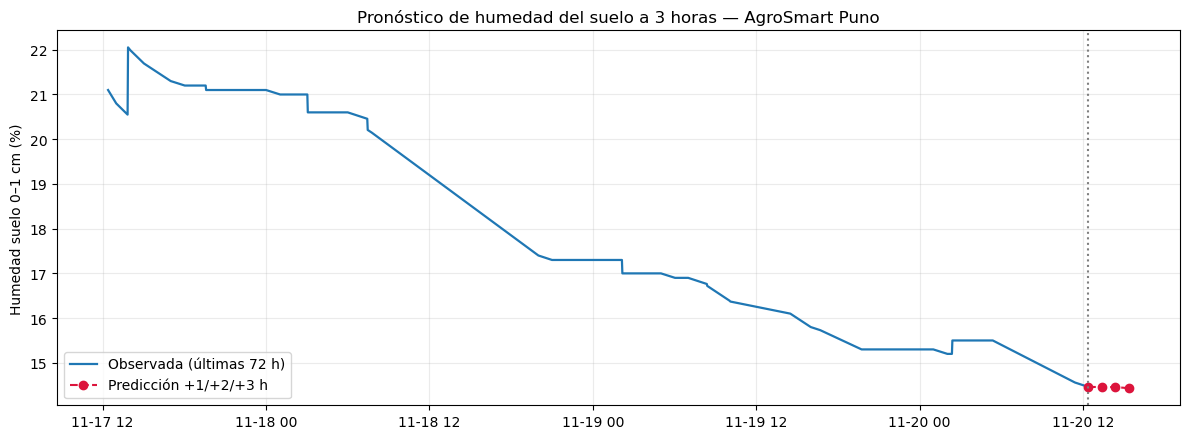

In [23]:
hist = sql('''SELECT fecha_evento, humedad_suelo_pct FROM eventos_telemetria WHERE fecha_evento <= NOW()
               AND fecha_evento >= NOW() - INTERVAL '72 hours' ORDER BY fecha_evento''')
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(hist.fecha_evento, hist.humedad_suelo_pct, label='Observada (últimas 72 h)', lw=1.6)
ax.plot([f0] + list(pron_df.fecha_objetivo), [float(ult.humedad_suelo_pct)] + list(pron_df.prediccion_pct), 'o--', color='crimson', label='Predicción +1/+2/+3 h')
ax.axvline(f0, color='gray', ls=':'); ax.set_ylabel('Humedad suelo 0–1 cm (%)'); ax.grid(alpha=.25); ax.legend()
ax.set_title('Pronóstico de humedad del suelo a 3 horas — AgroSmart Puno'); plt.tight_layout()
fig.savefig(RAIZ/'resultados'/'pronostico_3h.png', dpi=170, bbox_inches='tight'); plt.show()

## 10.4 Naturaleza temporal de las predicciones guardadas y error real (cuando ya llegó la hora objetivo)

In [24]:
display(sql('''SELECT horizonte_h, COUNT(*) total, SUM(CASE WHEN es_retro THEN 1 ELSE 0 END) retrospectivas,
                      SUM(CASE WHEN NOT es_retro THEN 1 ELSE 0 END) prospectivas FROM predicciones_humedad GROUP BY horizonte_h ORDER BY 1'''))
ev = sql('''SELECT p.horizonte_h, p.prediccion_pct, t.humedad_suelo_pct AS observada
            FROM predicciones_humedad p JOIN eventos_telemetria t ON t.fecha_evento = p.fecha_objetivo
            WHERE t.origen='open_meteo_modelado' ''')
if len(ev):
    ev['err'] = ev.prediccion_pct - ev.observada
    display(ev.groupby('horizonte_h').agg(n=('err','size'), RMSE=('err', lambda e: float(np.sqrt((e**2).mean()))), MAE=('err', lambda e: float(e.abs().mean()))).round(4))
else: print('Aún no hay objetivos cumplidos con datos de la API; espera nuevas horas.')

,horizonte_h,total,retrospectivas,prospectivas
0,1,1640,796,844
1,2,1640,790,850
2,3,1640,788,852


,n,RMSE,MAE
horizonte_h,,,
1,84,0.9689,0.4081
2,80,1.2613,0.6752
3,78,1.4660,0.8882


---
# SESIÓN 11 · BI/ML distribuido con Spark y Grafana
El dashboard **`AgroSmart Puno U2 | Humedad del suelo — BI/ML v2`** (33 elementos: KPIs, telemetría, eventos, ventanas, predicción +1/+2/+3 h, comparación de 4 algoritmos, observabilidad y costos) ya viene **aprovisionado** en `obs/grafana/dashboards/agrosmart_u2.json`.

**Pasos en Grafana (http://localhost:3300):**
1. Inicia sesión (usuario/clave de `.env`).
2. *Dashboards → AgroSmart U2 →* **AgroSmart Puno U2 | Humedad del suelo — BI/ML v2**.
3. Rango de tiempo: **Last 180 days** (para ver la carga inicial + API). Para solo el seguimiento reciente: *Last 7 days*.
4. Si no apareciera: *Dashboards → New → Import → Upload JSON file* y elige `obs/grafana/dashboards/agrosmart_u2.json`; datasources: `AgroSmart PostgreSQL` y `AgroSmart Prometheus` (ya provisionados).
5. Panel **«Humedad observada frente a predicciones de +1 / +2 / +3 h»** = el pronóstico a 3 horas. Compara cada predicción **en su `fecha_objetivo`**.
6. Captura **un solo screenshot** con KPI + humedad + predicción + reloj del sistema (evidencia S11).

## 11.1 Los mismos datos que ve Grafana, desde el cuaderno (verificación cruzada)

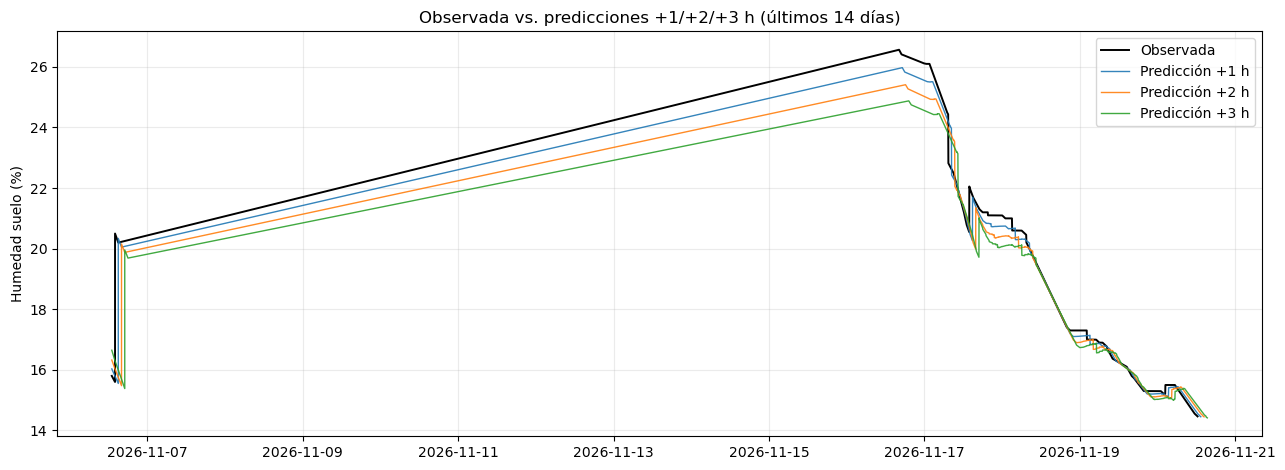

Exportado: /home/jovyan/work/Sensorhumedad/resultados/predicciones_humedad_export.csv 4923 filas


In [25]:
obs_df = sql("SELECT fecha_evento, humedad_suelo_pct FROM eventos_telemetria WHERE fecha_evento >= NOW() - INTERVAL '14 days' AND fecha_evento <= NOW() ORDER BY 1")
pr = {h: sql("SELECT fecha_objetivo, prediccion_pct FROM predicciones_humedad WHERE horizonte_h=%s AND fecha_objetivo >= NOW() - INTERVAL '14 days' ORDER BY 1", (h,)) for h in (1, 2, 3)}
fig, ax = plt.subplots(figsize=(13, 4.8)); ax.plot(obs_df.fecha_evento, obs_df.humedad_suelo_pct, color='k', lw=1.4, label='Observada')
for h, c in zip((1, 2, 3), ('tab:blue', 'tab:orange', 'tab:green')):
    if len(pr[h]): ax.plot(pr[h].fecha_objetivo, pr[h].prediccion_pct, color=c, lw=1, alpha=.9, label=f'Predicción +{h} h')
ax.set_ylabel('Humedad suelo (%)'); ax.grid(alpha=.25); ax.legend(); ax.set_title('Observada vs. predicciones +1/+2/+3 h (últimos 14 días)'); plt.tight_layout(); plt.show()
exp = sql('''SELECT p.horizonte_h, p.fecha_evento, p.fecha_objetivo, p.prediccion_pct, t.humedad_suelo_pct observada, p.es_retro, p.modelo
             FROM predicciones_humedad p LEFT JOIN eventos_telemetria t ON t.fecha_evento=p.fecha_objetivo ORDER BY p.fecha_objetivo DESC, p.horizonte_h''')
exp.to_csv(RAIZ/'resultados'/'predicciones_humedad_export.csv', index=False); print('Exportado:', RAIZ/'resultados'/'predicciones_humedad_export.csv', len(exp), 'filas')